# Лабораторна робота №2. Аналіз часових рядів
**Варіант 13**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

In [2]:
np.random.seed(42)
v = np.random.normal(0, 1, 100)
y = np.zeros(100)
y[:3] = v[:3]

a0, a1, a2, a3 = 0.10, 0.21, 0.32, 0.43
b1, b2, b3 = 0.40, 0.40, 0.20

for t in range(3, 100):
    y[t] = (a0 + a1*y[t-1] + a2*y[t-2] + a3*y[t-3]
            + v[t] + b1*v[t-1] + b2*v[t-2] + b3*v[t-3])

display(pd.DataFrame({'v': v, 'y': y}).head(10).round(3))

,v,y
0,0.497,0.497
1,-0.138,-0.138
2,0.648,0.648
3,1.523,2.231
4,-0.234,1.323
5,-0.234,1.781
6,1.579,3.553
7,0.767,3.244
8,-0.469,3.107
9,0.543,4.296


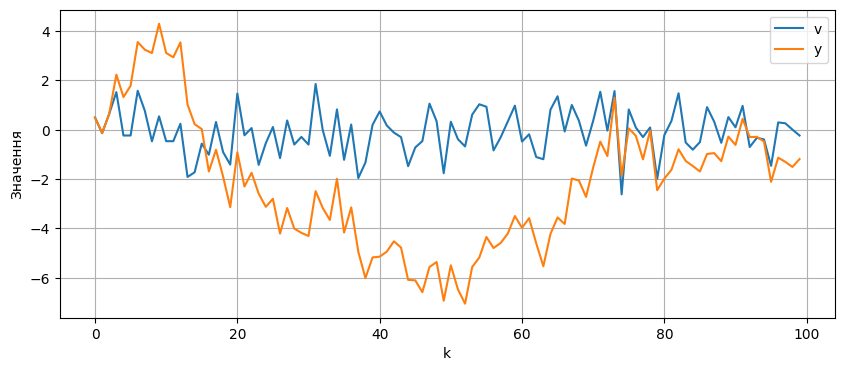

In [3]:
plt.figure(figsize=(10, 4))
plt.plot(v, label='v')
plt.plot(y, label='y')
plt.xlabel('k')
plt.ylabel('Значення')
plt.legend()
plt.grid()
plt.show()

In [4]:
rtsmm = np.loadtxt('Data/RTSmm.txt')
rts2007 = np.loadtxt('Data/2007rts1.txt')

print('RTSmm:', len(rtsmm), 'значень')
print('2007rts1:', len(rts2007), 'значень')

RTSmm: 178 значень
2007rts1: 248 значень


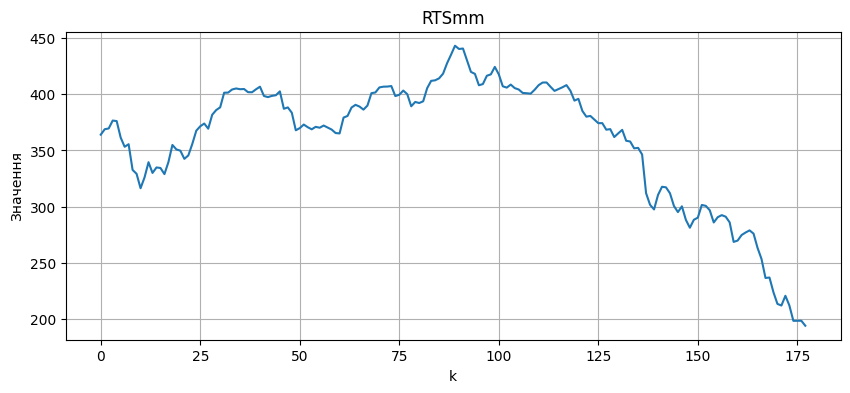

In [5]:
plt.figure(figsize=(10, 4))
plt.plot(rtsmm)
plt.title('RTSmm')
plt.xlabel('k')
plt.ylabel('Значення')
plt.grid()
plt.show()

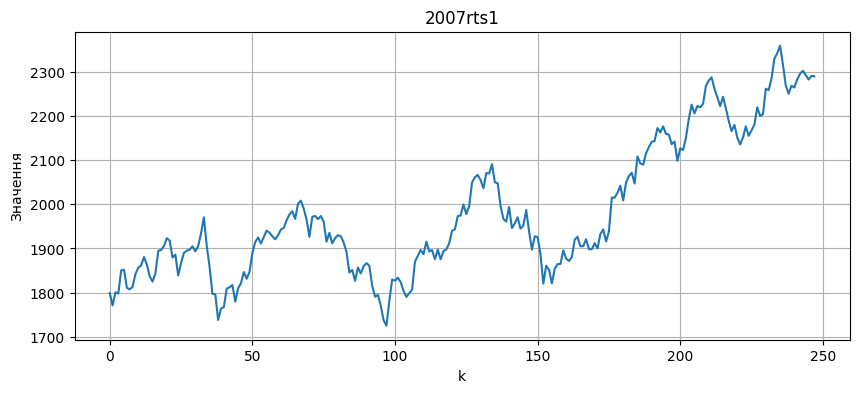

In [6]:
plt.figure(figsize=(10, 4))
plt.plot(rts2007)
plt.title('2007rts1')
plt.xlabel('k')
plt.ylabel('Значення')
plt.grid()
plt.show()

## Просте та експоненційне ковзне середнє

$$
SMA(k)=\frac{\sum_{i=1}^{N}y(k-i+1)}{N}
$$

$$
EMA(k)=\frac{\sum_{i=1}^{N}w_i\cdot y(k-i+1)}{\sum_{i=1}^{N}w_i}
$$

$$
w_i=(1-\alpha)^{N-i+1}
$$

$$
\alpha=\frac{2}{N+1}
$$

In [7]:
def SMA(x, n):
    result = np.full(len(x), np.nan)
    for t in range(n - 1, len(x)):
        result[t] = np.mean(x[t-n+1:t+1])
    return result


def EMA(x, n):
    alpha = 2 / (n + 1)
    weights = (1 - alpha) ** np.arange(1, n + 1)
    weights = weights / weights.sum()

    result = np.full(len(x), np.nan)

    for t in range(n - 1, len(x)):
        result[t] = np.sum(x[t-n+1:t+1] * weights)

    return result, weights

In [8]:
rtsmm_sma5 = SMA(rtsmm, 5)
rtsmm_sma10 = SMA(rtsmm, 10)

rtsmm_ema5, weights5 = EMA(rtsmm, 5)
rtsmm_ema10, weights10 = EMA(rtsmm, 10)

rts2007_sma5 = SMA(rts2007, 5)
rts2007_sma10 = SMA(rts2007, 10)

rts2007_ema5, _ = EMA(rts2007, 5)
rts2007_ema10, _ = EMA(rts2007, 10)

In [9]:
table_weights = pd.DataFrame({
    'EMA(5)': np.append(weights5[::-1], [np.nan] * 5),
    'EMA(10)': weights10[::-1]
})

display(table_weights.round(4))

,EMA(5),EMA(10)
0,0.0758,0.0345
1,0.1137,0.0422
2,0.1706,0.0516
3,0.2559,0.0630
4,0.3839,0.0770
5,NaN,0.0941
6,NaN,0.1150
7,NaN,0.1406
8,NaN,0.1719
9,NaN,0.2101


In [10]:
table_rtsmm = pd.DataFrame({
    'RTSmm': rtsmm, 'SMA(5)': rtsmm_sma5, 'EMA(5)': rtsmm_ema5,
    'SMA(10)': rtsmm_sma10, 'EMA(10)': rtsmm_ema10
})
table_2007 = pd.DataFrame({
    '2007rts1': rts2007, 'SMA(5)': rts2007_sma5, 'EMA(5)': rts2007_ema5,
    'SMA(10)': rts2007_sma10, 'EMA(10)': rts2007_ema10
})

print('RTSmm')
display(table_rtsmm.head(12).round(2))
print('2007rts1')
display(table_2007.head(12).round(2))

RTSmm


,RTSmm,SMA(5),EMA(5),SMA(10),EMA(10)
0,363.97,NaN,NaN,NaN,NaN
1,368.81,NaN,NaN,NaN,NaN
2,369.50,NaN,NaN,NaN,NaN
3,376.52,NaN,NaN,NaN,NaN
4,376.05,370.97,368.50,NaN,NaN
5,361.46,370.47,370.57,NaN,NaN
6,353.22,367.35,370.27,NaN,NaN
7,355.50,364.55,369.59,NaN,NaN
8,332.66,355.78,362.79,NaN,NaN
9,329.21,346.41,352.61,358.69,364.33


2007rts1


,2007rts1,SMA(5),EMA(5),SMA(10),EMA(10)
0,1798.63,NaN,NaN,NaN,NaN
1,1770.67,NaN,NaN,NaN,NaN
2,1800.61,NaN,NaN,NaN,NaN
3,1797.59,NaN,NaN,NaN,NaN
4,1850.21,1803.54,1795.61,NaN,NaN
5,1851.63,1814.14,1798.11,NaN,NaN
6,1810.63,1822.13,1814.86,NaN,NaN
7,1807.28,1823.47,1822.49,NaN,NaN
8,1812.93,1826.54,1836.11,NaN,NaN
9,1841.97,1824.89,1828.44,1814.22,1806.22


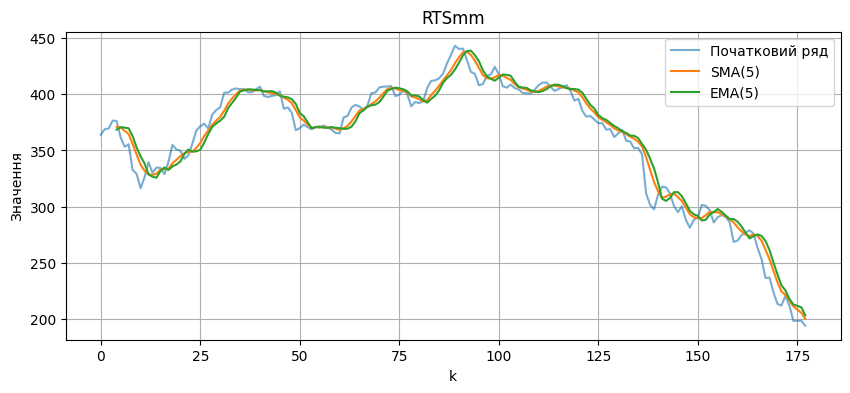

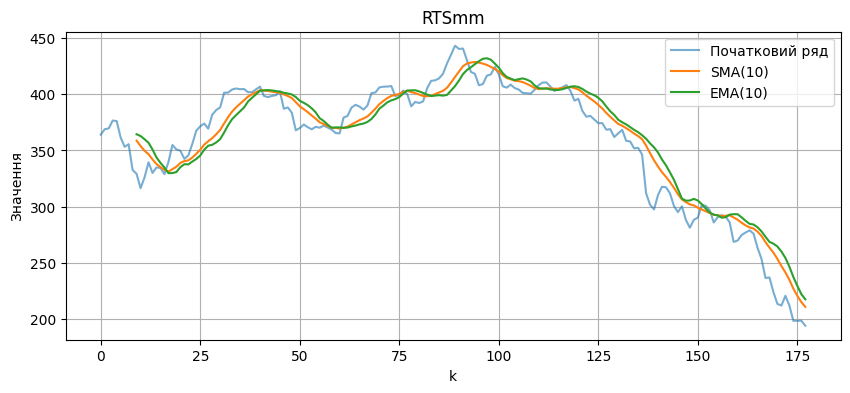

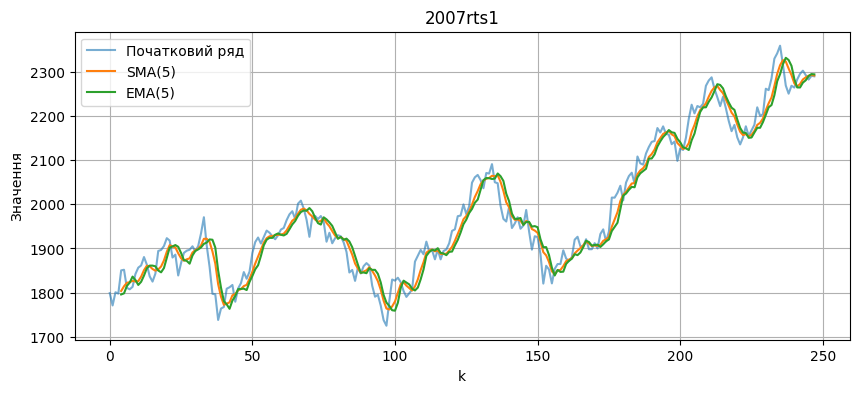

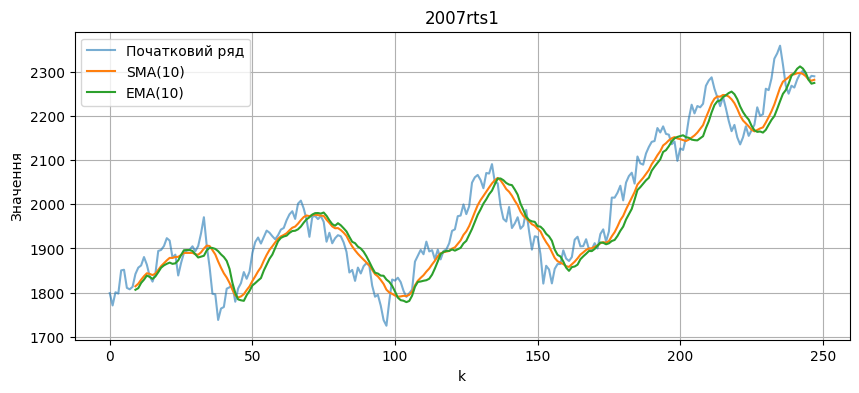

In [11]:
def plot_ma(x, sma, ema, name, n):
    plt.figure(figsize=(10, 4))
    plt.plot(x, label='Початковий ряд', alpha=0.6)
    plt.plot(sma, label='SMA(' + str(n) + ')')
    plt.plot(ema, label='EMA(' + str(n) + ')')
    plt.title(name)
    plt.xlabel('k')
    plt.ylabel('Значення')
    plt.legend()
    plt.grid()
    plt.show()


plot_ma(rtsmm, rtsmm_sma5, rtsmm_ema5, 'RTSmm', 5)
plot_ma(rtsmm, rtsmm_sma10, rtsmm_ema10, 'RTSmm', 10)
plot_ma(rts2007, rts2007_sma5, rts2007_ema5, '2007rts1', 5)
plot_ma(rts2007, rts2007_sma10, rts2007_ema10, '2007rts1', 10)

## Автокореляційна функція ACF

$$
r_s=\frac{1}{N-1}\frac{\sum_{k=s+1}^{N}(y(k)-\bar{y})(y(k-s)-\bar{y})}{\sigma_y^2}
$$

In [12]:
def ACF(x, max_lag):
    n = len(x)
    mean = np.mean(x)
    variance = np.sum((x - mean) ** 2) / (n - 1)
    result = [1.0]
    for s in range(1, max_lag + 1):
        numerator = np.sum((x[s:] - mean) * (x[:-s] - mean))
        result.append(numerator / ((n - 1) * variance))
    return np.array(result)


acf_rtsmm = ACF(rtsmm, 12)
acf_2007 = ACF(rts2007, 12)

## Часткова автокореляційна функція PACF

Для першого лагу:

$$
\Phi_1=r_1
$$

Для $k>1$:

$$
\Phi_k=\frac{r_k-\sum_{j=1}^{k-1}\Phi_{k-1,j}\cdot r_{k-j}}{1-\sum_{j=1}^{k-1}\Phi_{k-1,j}\cdot r_j}
$$
де
$$
\Phi_{k,j}=\Phi_{k-1,j}-\Phi_k\cdot\Phi_{k-1,k-j}
$$

In [18]:
def PACF(r):
    result = [1.0]
    phi = np.array([])

    for k in range(1, len(r)):
        numerator = r[k] - np.dot(phi, r[1:k][::-1])
        denominator = 1 - np.dot(phi, r[1:k])
        new_phi = numerator / denominator

        phi = np.append(phi - new_phi * phi[::-1], new_phi)
        result.append(new_phi)

    return np.array(result)

In [19]:
pacf_rtsmm = PACF(acf_rtsmm)
pacf_2007 = PACF(acf_2007)

cor_rtsmm = pd.DataFrame({'ACF': acf_rtsmm, 'PACF': pacf_rtsmm
})
cor_2007 = pd.DataFrame({'ACF': acf_2007, 'PACF': pacf_2007
})

print('RTSmm')
display(cor_rtsmm.round(4))
print('2007rts1')
display(cor_2007.round(4))

RTSmm


,ACF,PACF
0,1.0000,1.0000
1,0.9683,0.9683
2,0.9342,-0.0553
3,0.8993,-0.0289
4,0.8636,-0.0305
5,0.8330,0.0638
6,0.8027,-0.0174
7,0.7682,-0.0875
8,0.7331,-0.0259
9,0.6998,0.0183


2007rts1


,ACF,PACF
0,1.0000,1.0000
1,0.9749,0.9749
2,0.9479,-0.0495
3,0.9218,0.0042
4,0.8961,-0.0063
5,0.8696,-0.0294
6,0.8479,0.0848
7,0.8240,-0.0661
8,0.8014,0.0199
9,0.7761,-0.0675


## Порівняння PACF зі statsmodels

In [21]:
from statsmodels.tsa.stattools import pacf as sm_pacf

pacf_sm_rtsmm = sm_pacf(rtsmm)[:13]
pacf_sm_2007 = sm_pacf(rts2007)[:13]

print('RTSmm')
display(pd.DataFrame({
    'PACF (власна)': pacf_rtsmm,
    'PACF (statsmodels)': pacf_sm_rtsmm
}).round(4))

print('2007rts1')
display(pd.DataFrame({
    'PACF (власна)': pacf_2007,
    'PACF (statsmodels)': pacf_sm_2007
}).round(4))

RTSmm


,PACF (власна),PACF (statsmodels)
0,1.0000,1.0000
1,0.9683,0.9738
2,-0.0553,-0.0669
3,-0.0289,-0.0341
4,-0.0305,-0.0364
5,0.0638,0.0808
6,-0.0174,-0.0227
7,-0.0875,-0.1100
8,-0.0259,-0.0310
9,0.0183,0.0276


2007rts1


,PACF (власна),PACF (statsmodels)
0,1.0000,1.0000
1,0.9749,0.9788
2,-0.0495,-0.0587
3,0.0042,0.0059
4,-0.0063,-0.0073
5,-0.0294,-0.0351
6,0.0848,0.1040
7,-0.0661,-0.0827
8,0.0199,0.0271
9,-0.0675,-0.0841


$$
EMA(k)=\frac{\sum_{i=1}^{N}w_i\cdot y(k-N+i)}{\sum_{i=1}^{N}w_i}
$$

$$
w_i=(1-\alpha)^{N-i+1}
$$

$$
\alpha=\frac{2}{N+1}
$$

In [15]:
def EMA(x, n):
    alpha = 2 / (n + 1)
    weights = (1 - alpha) ** np.arange(n, 0, -1)
    weights = weights / weights.sum()

    result = np.full(len(x), np.nan)

    for t in range(n - 1, len(x)):
        result[t] = np.sum(x[t-n+1:t+1] * weights)

    return result, weights

In [16]:
rtsmm_ema5, weights5 = EMA(rtsmm, 5)
rtsmm_ema10, weights10 = EMA(rtsmm, 10)

rts2007_ema5, _ = EMA(rts2007, 5)
rts2007_ema10, _ = EMA(rts2007, 10)

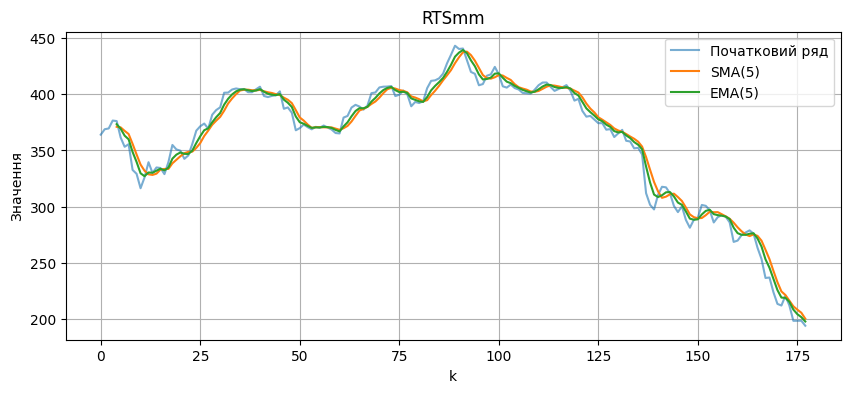

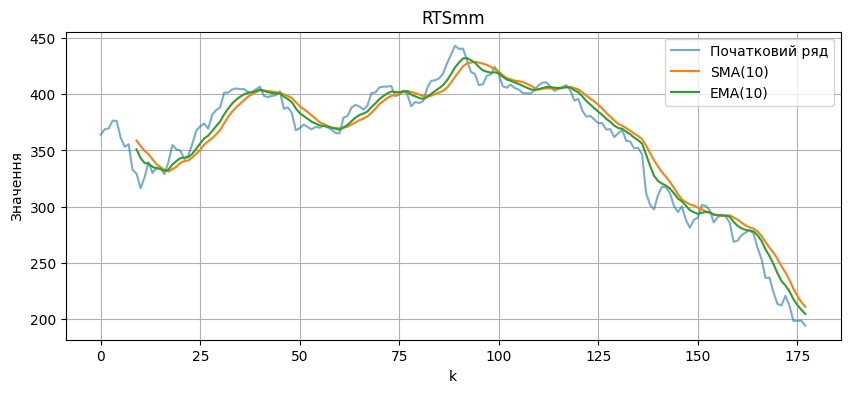

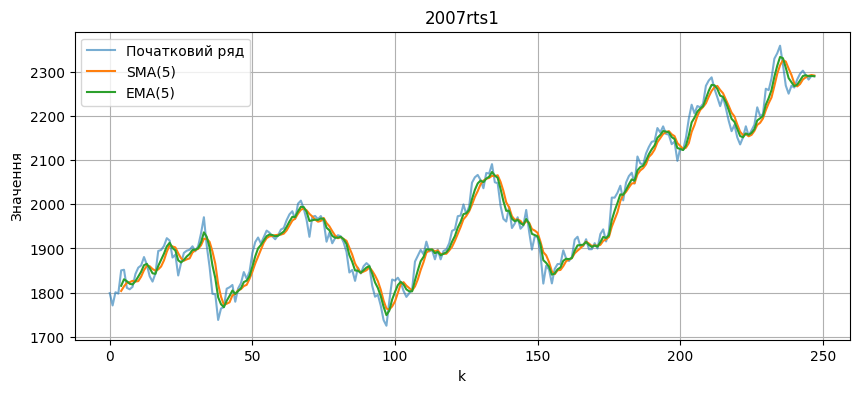

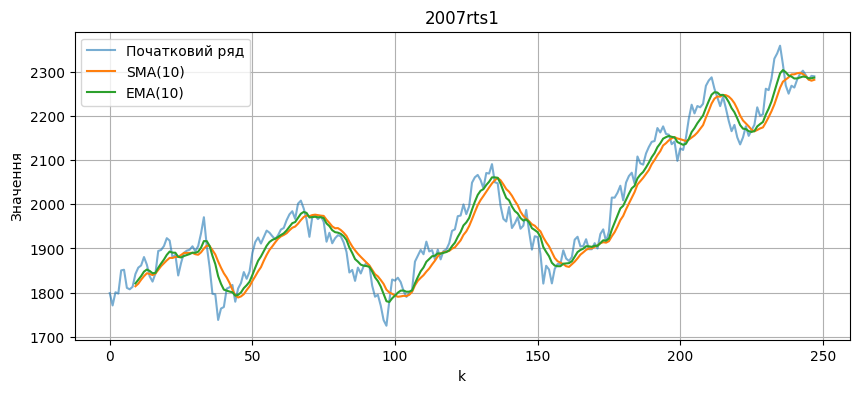

In [17]:
plot_ma(rtsmm, rtsmm_sma5, rtsmm_ema5, 'RTSmm', 5)
plot_ma(rtsmm, rtsmm_sma10, rtsmm_ema10, 'RTSmm', 10)
plot_ma(rts2007, rts2007_sma5, rts2007_ema5, '2007rts1', 5)
plot_ma(rts2007, rts2007_sma10, rts2007_ema10, '2007rts1', 10)